# Selección de modelos OLS · propiedades usadas

[1. Datos](#1.-Datos) · [2. Forward Selection](#2.-Forward-Selection) · [3. Group Lasso + OLS](#3.-Group-Lasso-+-OLS) · [4. Backward Selection](#4.-Backward-Selection) · [5. Forward — 177 predictoras](#5.-Forward-Stepwise-Selection-—-177-predictoras) · [6. Group Lasso + OLS — 177](#6.-Group-Lasso-+-OLS-—-177-predictoras) · [7. Comparación final](#7.-Comparación-final)

## 1. Datos
Se utiliza exclusivamente `data/train_transformado.csv`, generado en `2_Transformacion_PropUsadas.ipynb`: **177 columnas predictoras exportadas → 174 candidatas**, tras excluir `to_center_km`, `living_area` y `rooms`.
Forward y Group Lasso mantienen las exclusiones históricas centralizadas en `s.EXCLUIDAS`; `EXCLUIDAS=()` habilita las 177, pero exige nueva selección y nombres de Run nuevos: los modelos históricos se rechazan si cambia la configuración.
El objetivo es `ln(price_rub)`; las predicciones en RUB usan `exp` sin corrección de sesgo. No se repite la preparación del CSV y Test permanece reservado.
Los tres métodos comparten la partición interna fija 80/20 de Train (semilla 42). El OLS definitivo conserva las columnas transformadas exportadas.
El grupo original `date_posted_dt` representa la columna derivada `months_since_start`; la fecha auxiliar no entra directamente al modelo.

Backward utiliza las **177 columnas**, incluidas `to_center_km`, `living_area` y `rooms`, con exclusiones vacías propias. Los universos diferentes impiden atribuir las diferencias exclusivamente al algoritmo.

El nuevo Forward utiliza un universo independiente de 177 columnas; el Forward histórico conserva sus 174 candidatas y su Run original. Los cinco experimentos comparten los mismos índices de validación interna.

Group Lasso + OLS de 177 candidatas utiliza el nuevo Forward como referencia y mantiene un espacio temporal independiente.


In [1]:
from pathlib import Path
import sys
from IPython.display import display, Markdown, Image
paquete = next(c for p in (Path.cwd(), *Path.cwd().parents)
               for c in (p, p / "Ventas/Propiedades_Usadas") if (c / "scripts/__init__.py").is_file())
if str(paquete) not in sys.path: sys.path.insert(0, str(paquete))
from scripts import seleccion_modelos as s, backward_ols as bw, group_lasso_ols as gl
from scripts.almacenamiento_mlflow import SesionTemporal
from scripts.contrato_datasets import CARPETA_PROYECTO as base
EXCLUIDAS, MODO = s.EXCLUIDAS, "recuperar"  # Cambiar a 177 requiere EXCLUIDAS=(), modo nuevo y Runs nuevos.
sesion = SesionTemporal()
with sesion.paso():
    datos = s.cargar_presentacion(base, sesion, excluidas=EXCLUIDAS)
print(f"Observaciones: {len(datos['y']):,} · Candidatas: {datos['n_exportadas']} − {len(EXCLUIDAS)} = {datos['X'].shape[1]} columnas, {len(datos['grupos'])} grupos")
print("Características candidatas: " + ", ".join(datos['grupos']))
print("Objetivo: ln(price_rub)")


Observaciones: 37,984 · Candidatas: 177 − 3 = 174 columnas, 20 grupos
Características candidatas: total_area, kitchen_area, floor, total_floors, building_year, ceiling_height, metro_distance_min, metro_to_center_km, mortgage_key_rate_at_listing, surface_corrected, secondary_mom_change_pct, has_balcony, metro_distance_type, seller_type, building_type, renovation, metro_line, district, date_posted_dt, month_of_year
Objetivo: ln(price_rub)


## 2. Forward Selection
Incorpora progresivamente el grupo que más reduce el RMSE de validación interna en RUB: máximo **12 características**, mejora mínima **0,5 %**.
Cada bloque One-Hot se selecciona completo como una característica original.
El modo actual **recupera la selección y el OLS históricos de MLflow**; `modo="nuevo"` ejecuta el procedimiento y exige un nombre de Run libre mediante `nombre_run`.


In [2]:
with sesion.paso():
    forward = s.ejecutar_presentacion(datos, "forward", modo=MODO)


In [3]:
display(Markdown(forward['caracteristicas_md']))


| Característica seleccionada | Cantidad de predictores |
|---|---|
| `district` | 128 |
| `total_area` | 1 |
| `renovation` | 3 |
| `date_posted_dt` | 1 |
| `building_type` | 5 |
| `metro_distance_min` | 1 |
| `metro_distance_type` | 1 |
| Total: 7 características | 140 predictores |

In [4]:
display(Markdown(s.tabla_metricas_presentacion(forward)))


| Evaluación | Métrica | Forward |
|---|---|---|
| Train | R² [ln(RUB)] | 0.953577 |
| Train | R² ajustado [ln(RUB)] | 0.953405 |
| Train | MAE (RUB) | 1,116,830.765 |
| Train | RMSE (RUB) | 1,609,441.446 |
| Train | AIC [ln(RUB)] | -52,883.105 |
| Train | BIC [ln(RUB)] | -51,678.271 |
| Train | VIF máximo | 8.554 |
| Train | Número de condición | 13,160.607 |
| Train | Breusch–Pagan (p) | 2.337e-87 |
| Train | Jarque–Bera (p) | 2.214e-65 |
| Validación interna | RMSE (RUB) | 1,612,615.151 |

In [5]:
display(Markdown(s.interpretar_presentacion(forward)))


El OLS utiliza 7 características originales y 140 columnas predictoras, más el intercepto.  
R² ajustado log=0.95341; RMSE Train=1,609,441 RUB y validación interna=1,612,615 RUB.  
Persisten límites de homocedasticidad (BP p=2.34e-87) y normalidad (JB p=2.21e-65).  
La validación se utilizó para seleccionar: sus métricas no son una evaluación independiente. exp sin corrección puede sesgar el precio esperado.

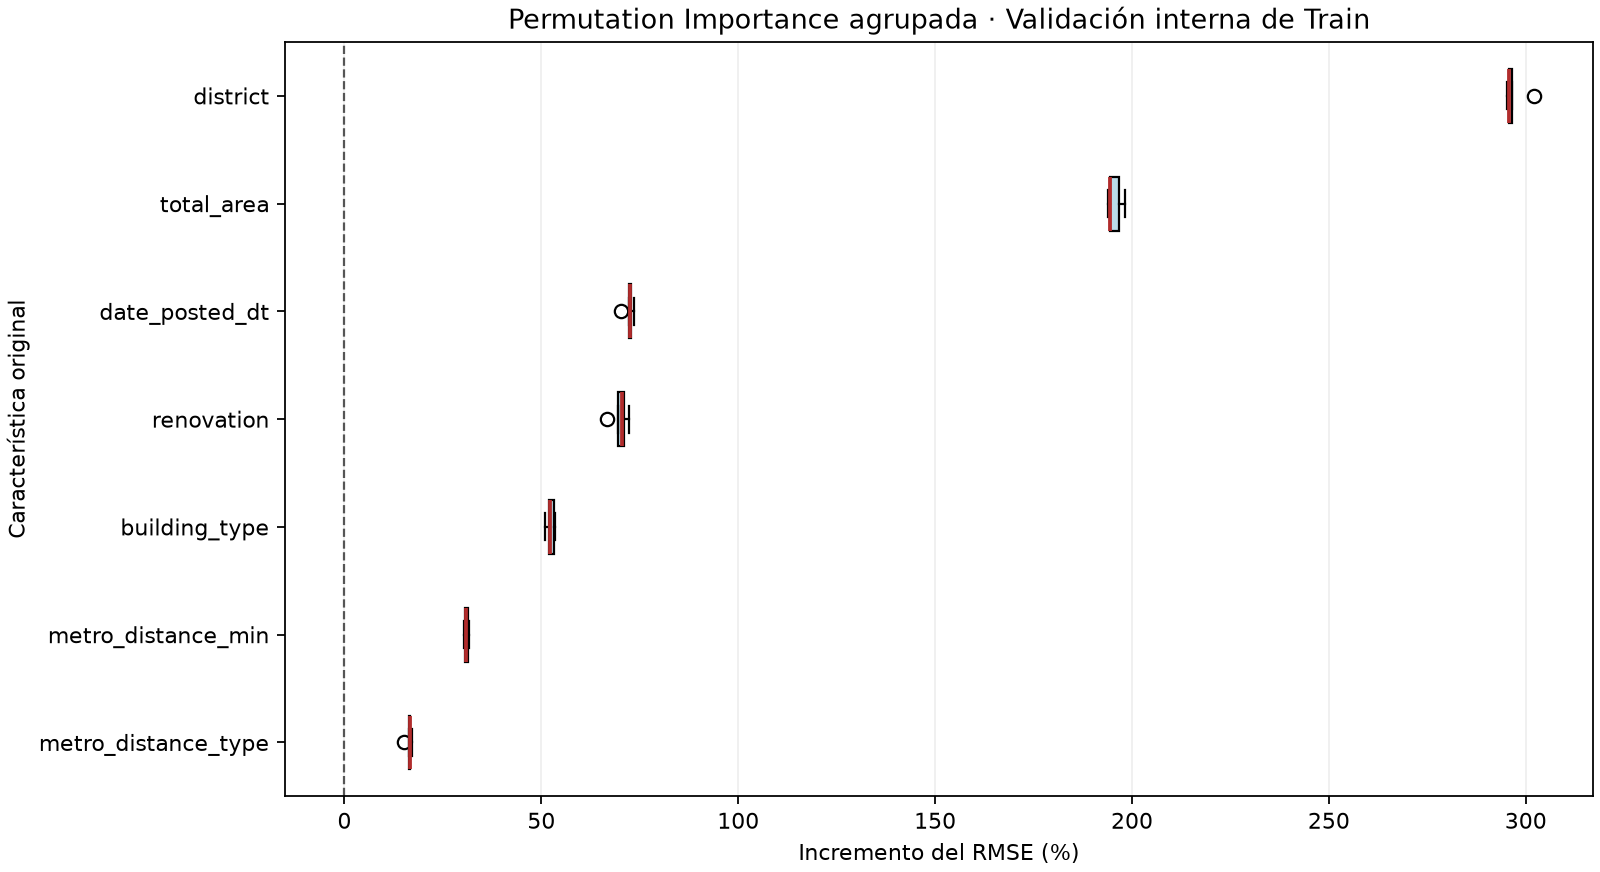

Mayores medianas de incremento del RMSE: `district` (295.7 %), `total_area` (194.5 %), `date_posted_dt` (72.5 %); 5 permutaciones por grupo.  
Las columnas de cada grupo se permutan conjuntamente respecto de price_rub; no mide efectos causales ni magnitudes de coeficientes OLS.  
Se reutiliza la validación de selección; correlaciones entre características pueden afectar la importancia.

In [6]:
display(Image(filename=str(forward['salida'] / 'importancia_caracteristicas_boxplot.png')))
display(Markdown(s.interpretar_importancia(forward)))


In [7]:
display(Markdown(s.confirmacion_presentacion(forward)))


Recuperado de MLflow; sin nueva selección ni ajuste final · **FINISHED** · [Forward_01_Log_Grupos](https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/5/runs/d43e88406b0843c5b7963d2c1e62d15a)

## 3. Group Lasso + OLS
La regularización selecciona grupos completos (incluidos los bloques One-Hot); después se ajusta un OLS sin penalización con las características elegidas.
Se evalúan **40 lambdas**, desde λmáx hasta 0,001 × λmáx. Los subconjuntos se comparan por RMSE interno en RUB, con máximo **12 grupos** y mejora mínima **0,5 %** entre complejidades aceptadas; se evalúa la grilla completa.
El escalado propio de la selección se ajusta solo en el entrenamiento interno; el OLS final conserva las escalas exportadas. Se comparte la partición de Forward.
El modo actual **recupera el Run histórico**; `modo="nuevo"` ejecuta la búsqueda y el OLS con un nombre de Run nuevo.


In [8]:
with sesion.paso():
    lasso = s.ejecutar_presentacion(datos, "lasso", modo=MODO, anterior=forward)


In [9]:
display(Markdown(lasso['caracteristicas_md']))


| Característica seleccionada | Cantidad de predictores |
|---|---|
| `total_area` | 1 |
| `ceiling_height` | 1 |
| `metro_distance_min` | 1 |
| `metro_to_center_km` | 1 |
| `surface_corrected` | 1 |
| `has_balcony` | 1 |
| `metro_distance_type` | 1 |
| `building_type` | 5 |
| `renovation` | 3 |
| `district` | 128 |
| `date_posted_dt` | 1 |
| Total: 11 características | 144 predictores |

In [10]:
display(Markdown(s.tabla_metricas_presentacion(lasso, anterior=forward)))


| Evaluación | Métrica | Forward | Group Lasso + OLS | Δ nuevo − anterior |
|---|---|---|---|---|
| Train | R² [ln(RUB)] | 0.953577 | 0.954765 | 0.001188 |
| Train | R² ajustado [ln(RUB)] | 0.953405 | 0.954592 | 0.001187 |
| Train | MAE (RUB) | 1,116,830.765 | 1,104,234.841 | -12,595.924 |
| Train | RMSE (RUB) | 1,609,441.446 | 1,592,884.139 | -16,557.307 |
| Train | AIC [ln(RUB)] | -52,883.105 | -53,859.677 | -976.572 |
| Train | BIC [ln(RUB)] | -51,678.271 | -52,620.664 | -942.393 |
| Train | VIF máximo | 8.554 | 10.369 | 1.815 |
| Train | Número de condición | 13,160.607 | 13,237.461 | 76.854 |
| Train | Breusch–Pagan (p) | 2.337e-87 | 8.128e-117 | -2.337e-87 |
| Train | Jarque–Bera (p) | 2.214e-65 | 2.745e-51 | 2.745e-51 |
| Validación interna | RMSE (RUB) | 1,612,615.151 | 1,593,947.716 | -18,667.436 |

In [11]:
display(Markdown(s.interpretar_presentacion(lasso, anterior=forward)))


El OLS utiliza 11 características originales y 144 columnas predictoras, más el intercepto.  
R² ajustado log=0.95459; RMSE Train=1,592,884 RUB y validación interna=1,593,948 RUB.  
Frente a Forward, cambia +4 características y el RMSE interno -1.158 %; no simplifica el modelo.  
Persisten límites de homocedasticidad (BP p=8.13e-117) y normalidad (JB p=2.75e-51).  
La validación se utilizó para seleccionar: sus métricas no son una evaluación independiente. exp sin corrección puede sesgar el precio esperado.

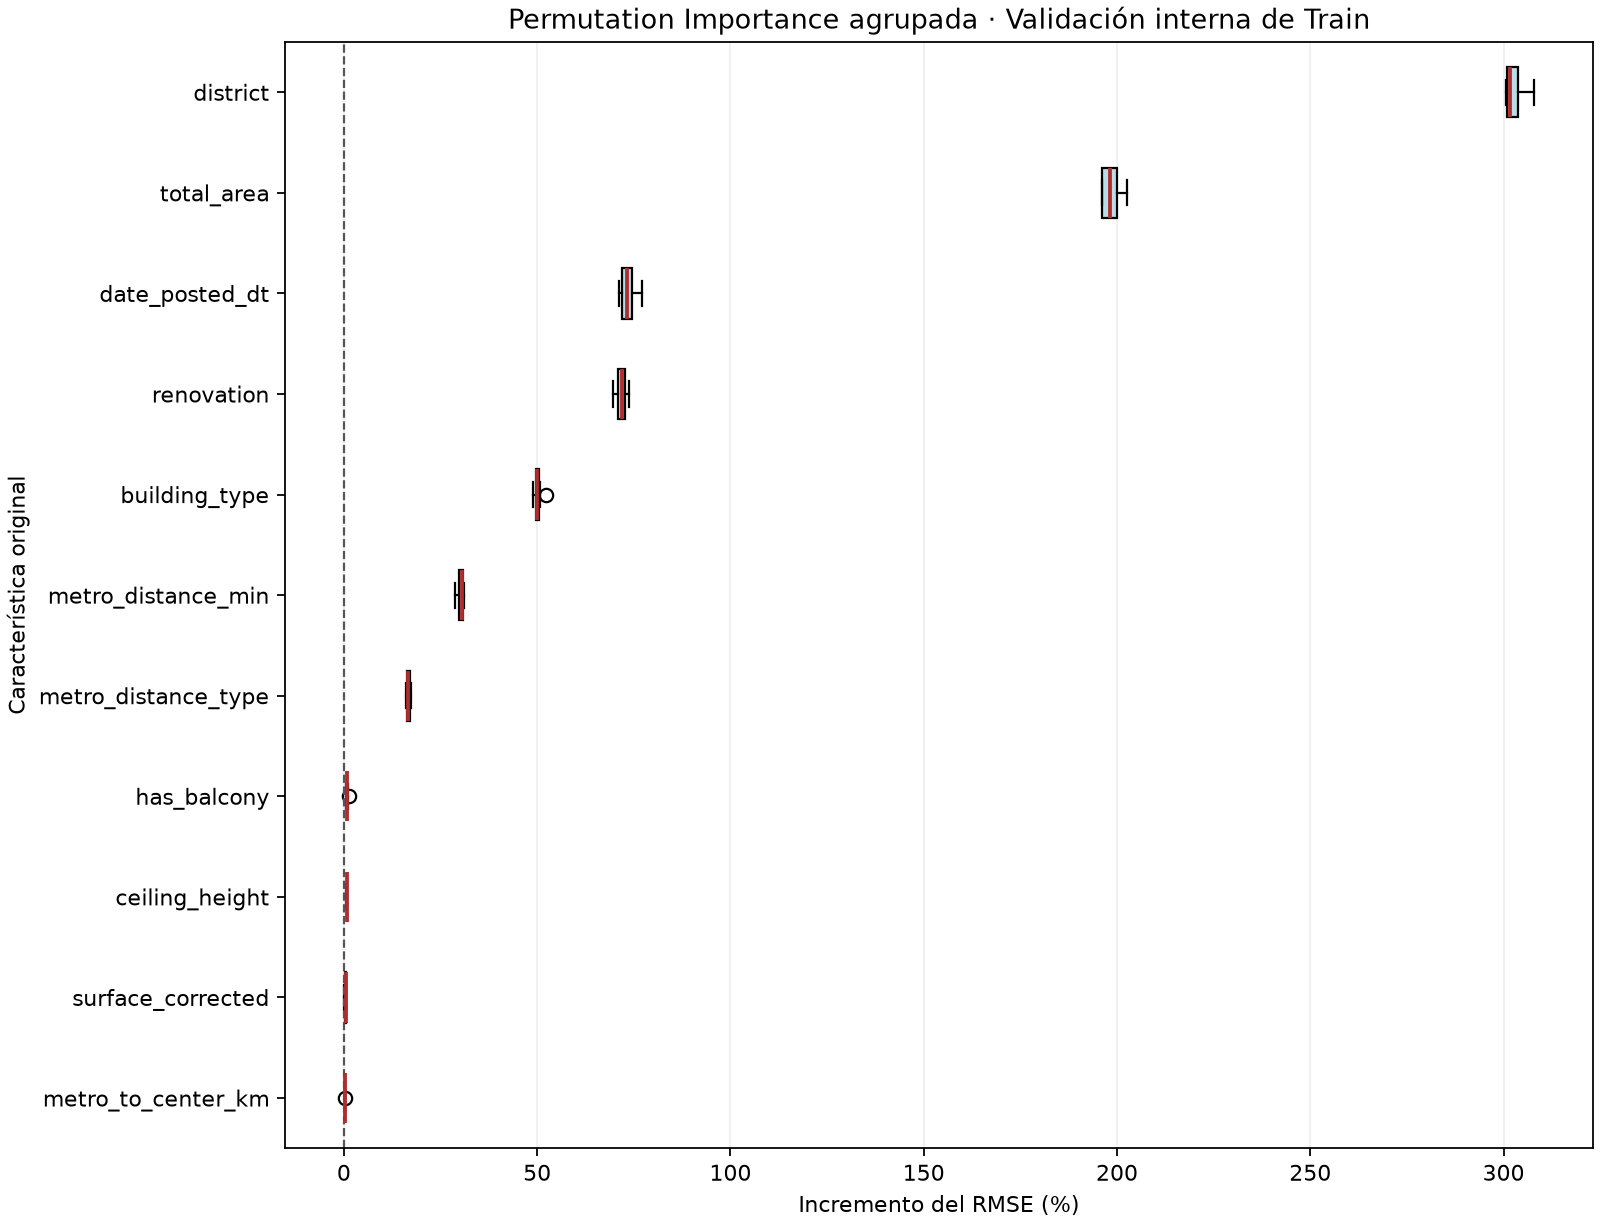

Mayores medianas de incremento del RMSE: `district` (301.7 %), `total_area` (198.3 %), `date_posted_dt` (73.3 %); 10 permutaciones por grupo.  
Las columnas de cada grupo se permutan conjuntamente respecto de price_rub; no mide efectos causales ni magnitudes de coeficientes OLS.  
Se reutiliza la validación de selección; correlaciones entre características pueden afectar la importancia.

In [12]:
display(Image(filename=str(lasso['salida'] / 'importancia_caracteristicas_boxplot.png')))
display(Markdown(s.interpretar_importancia(lasso)))


In [13]:
display(Markdown(s.confirmacion_presentacion(lasso)))


Recuperado de MLflow; sin nueva selección ni ajuste final · **FINISHED** · [GroupLasso_02_Log_Grupos_OLS](https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/5/runs/ac9faf6b61db4a7f8e274553199c5658)

## 4. Backward Selection
Parte de **177 columnas predictoras y un intercepto**, agrupadas por el linaje original; cada bloque One-Hot es indivisible. Referencia histórica: `OLS_02_Log_Target`.
En cada paso se elimina el grupo cuyo retiro produce el menor RMSE interno en RUB (`exp`, sin corrección), aun cuando implique deterioro. Se recorre hasta un grupo; después se evalúan los tamaños identificables de 1 a 12 en orden creciente, aceptando mejoras de al menos **0,5 %** frente al último aceptado, desde el intercepto. Un rechazo no detiene tamaños posteriores. No se eliminan columnas implícitamente por colinealidad; se registra el rango y el OLS definitivo debe ser identificable.
El Run exclusivo es `Backward_03_Log_177_Grupos_OLS`. La ejecución publicada se recupera con verificación estricta; una ejecución nueva requiere `modo="nuevo"` y un nombre libre. No se reentrenan los experimentos anteriores.


In [14]:
with sesion.paso():
    datos_backward = bw.cargar_datos(datos)
    backward = s.ejecutar_presentacion(datos_backward, "backward", modo="recuperar")


In [15]:
resumen, coeficientes = backward['caracteristicas_md'].split("\n\n", 1)
display(Markdown(resumen + "\n\n<details><summary>Columnas transformadas y coeficientes OLS</summary>\n\n"
                 + coeficientes + "\n\n</details>"))


| Característica seleccionada | Cantidad de predictores |
|---|---|
| `total_area` | 1 |
| `rooms` | 1 |
| `ceiling_height` | 1 |
| `metro_distance_min` | 1 |
| `to_center_km` | 1 |
| `surface_corrected` | 1 |
| `has_balcony` | 1 |
| `metro_distance_type` | 1 |
| `building_type` | 5 |
| `renovation` | 3 |
| `district` | 128 |
| `date_posted_dt` | 1 |
| Total: 12 características | 145 predictores |

<details><summary>Columnas transformadas y coeficientes OLS</summary>

| Característica original | Columna transformada | Coeficiente OLS [ln(RUB)] |
|---|---|---|
| total_area | total_area | 0.0158 |
| rooms | rooms | -0.0225 |
| ceiling_height | ceiling_height | 0.0456 |
| metro_distance_min | metro_distance_min | -0.0017 |
| to_center_km | to_center_km | -0.0078 |
| surface_corrected | surface_corrected | -0.1475 |
| has_balcony | has_balcony | 0.0309 |
| metro_distance_type | metro_distance_type | -0.1249 |
| building_type | building_type_khrushchev | -0.2102 |
| building_type | building_type_modern_panel | -0.0477 |
| building_type | building_type_monolith | 0.0454 |
| building_type | building_type_panel | -0.1322 |
| building_type | building_type_stalin | 0.1322 |
| renovation | renovation_designer | 0.3053 |
| renovation | renovation_euro | 0.1450 |
| renovation | renovation_no_renovation | -0.1110 |
| district | district_akademichesky | 0.1754 |
| district | district_alekseevsky | -0.0090 |
| district | district_altufyevsky | -0.2900 |
| district | district_arbat | 0.7328 |
| district | district_babushkinsky | -0.2064 |
| district | district_basmanny | 0.4852 |
| district | district_begovoy | 0.1387 |
| district | district_beskudnikovsky | -0.2679 |
| district | district_bibirevo | -0.2590 |
| district | district_biryulyovo_vostochnoye | -0.3662 |
| district | district_biryulyovo_zapadnoye | -0.3461 |
| district | district_bogorodskoye | -0.2132 |
| district | district_brateyevo | -0.3522 |
| district | district_butyrsky | -0.0668 |
| district | district_chertanovo_severnoye | -0.1933 |
| district | district_chertanovo_tsentralnoye | -0.2911 |
| district | district_chertanovo_yuzhnoye | -0.2024 |
| district | district_cheryomushki | 0.1799 |
| district | district_danilovsky | 0.0136 |
| district | district_desyonovskoye | -0.4765 |
| district | district_dmitrovsky | -0.3039 |
| district | district_donskoy | 0.0861 |
| district | district_dorogomilovo | 0.4668 |
| district | district_fili_davydkovo | 0.1820 |
| district | district_filimonkovskoye | -0.6095 |
| district | district_filyovsky_park | 0.2352 |
| district | district_gagarinsky | 0.3063 |
| district | district_golovinsky | -0.1959 |
| district | district_golyanovo | -0.2875 |
| district | district_ivanovskoye | -0.2787 |
| district | district_izmaylovo | -0.1124 |
| district | district_khamovniki | 0.7604 |
| district | district_khoroshyovo_mnyovniki | 0.1010 |
| district | district_khoroshyovsky | 0.1691 |
| district | district_khovrino | -0.2865 |
| district | district_kievsky | -0.5267 |
| district | district_klyonovskoye | -0.7022 |
| district | district_kokoshkino | -0.6138 |
| district | district_konkovo | 0.0240 |
| district | district_koptevo | -0.1861 |
| district | district_kosino_ukhtomsky | -0.3586 |
| district | district_kotlovka | 0.0692 |
| district | district_krasnopakhorskoye | -0.7580 |
| district | district_krasnoselsky | 0.4330 |
| district | district_krylatskoye | 0.2413 |
| district | district_kuntsevo | 0.0927 |
| district | district_kurkino | 0.0774 |
| district | district_levoberezhny | -0.1569 |
| district | district_lianozovo | -0.2879 |
| district | district_lomonosovsky | 0.3002 |
| district | district_losinoostrovsky | -0.2325 |
| district | district_marfino | -0.2210 |
| district | district_marushkinskoye | -0.6196 |
| district | district_maryina_roshcha | -0.0025 |
| district | district_meshchansky | 0.4762 |
| district | district_metrogorodok | -0.2752 |
| district | district_mikhaylovo_yartsevskoye | -0.7822 |
| district | district_mitino | -0.0607 |
| district | district_molzhaninovsky | -0.3541 |
| district | district_moskovsky | -0.4424 |
| district | district_moskvorechye_saburovo | -0.2254 |
| district | district_mosrentgen | -0.4054 |
| district | district_mozhaysky | 0.0164 |
| district | district_nagatino_sadovniki | -0.1233 |
| district | district_nagatinsky_zaton | -0.0938 |
| district | district_nagorny | -0.0607 |
| district | district_novo_peredelkino | -0.1646 |
| district | district_novofyodorovskoye | -0.5754 |
| district | district_novogireyevo | -0.1862 |
| district | district_novokosino | -0.2572 |
| district | district_obruchevsky | 0.1184 |
| district | district_ochakovo_matveyevskoye | 0.0111 |
| district | district_orekhovo_borisovo_severnoye | -0.3389 |
| district | district_orekhovo_borisovo_yuzhnoye | -0.3402 |
| district | district_ostankinsky | -0.0170 |
| district | district_otradnoye | -0.2159 |
| district | district_perovo | -0.0932 |
| district | district_pervomayskoye | -0.7127 |
| district | district_pokrovskoye_streshnevo | 0.0017 |
| district | district_preobrazhenskoye | -0.0413 |
| district | district_presnensky | 0.6805 |
| district | district_prospekt_vernadskogo | 0.3079 |
| district | district_ramenki | 0.3121 |
| district | district_rogovskoye | -0.5616 |
| district | district_rostokino | -0.2133 |
| district | district_ryazanovskoye | -0.5636 |
| district | district_savyolovsky | 0.0691 |
| district | district_severnoye_butovo | -0.1195 |
| district | district_severnoye_izmaylovo | -0.1517 |
| district | district_severnoye_medvedkovo | -0.2212 |
| district | district_severnoye_tushino | -0.1112 |
| district | district_severny | -0.3491 |
| district | district_shchapovskoye | -0.8357 |
| district | district_shcherbinka | -0.4657 |
| district | district_shchukino | 0.1878 |
| district | district_sokol | 0.1521 |
| district | district_sokolinaya_gora | -0.2184 |
| district | district_sokolniki | 0.0200 |
| district | district_solntsevo | -0.1093 |
| district | district_sosenskoye | -0.4350 |
| district | district_strogino | 0.2742 |
| district | district_sviblovo | -0.1775 |
| district | district_tagansky | 0.4445 |
| district | district_timiryazevsky | -0.0318 |
| district | district_troitsk | -0.6331 |
| district | district_troparyovo_nikulino | 0.2422 |
| district | district_tsaritsyno | -0.3001 |
| district | district_tverskoy | 0.7221 |
| district | district_tyoply_stan | -0.0312 |
| district | district_veshnyaki | -0.3671 |
| district | district_vnukovo | -0.1642 |
| district | district_vnukovskoye | -0.4366 |
| district | district_voronovskoye | -0.6237 |
| district | district_voskresenskoye | -0.5224 |
| district | district_vostochnoye_izmaylovo | -0.2178 |
| district | district_vostochny | -0.3772 |
| district | district_voykovsky | -0.0633 |
| district | district_yakimanka | 0.6752 |
| district | district_yaroslavsky | -0.2539 |
| district | district_yasenevo | 0.1463 |
| district | district_yuzhnoye_butovo | -0.1467 |
| district | district_yuzhnoye_medvedkovo | -0.2607 |
| district | district_yuzhnoye_tushino | -0.0547 |
| district | district_zamoskvorechye | 0.5589 |
| district | district_zapadnoye_degunino | -0.2978 |
| district | district_zelenograd | -0.4443 |
| district | district_zyablikovo | -0.3275 |
| district | district_zyuzino | 0.0295 |
| date_posted_dt | months_since_start | 0.0073 |

</details>

In [16]:
display(Markdown(s.tabla_metricas_presentacion(backward)))


| Evaluación | Métrica | Backward Selection |
|---|---|---|
| Train | R² [ln(RUB)] | 0.955399 |
| Train | R² ajustado [ln(RUB)] | 0.955228 |
| Train | MAE (RUB) | 1,096,985.003 |
| Train | RMSE (RUB) | 1,581,589.473 |
| Train | AIC [ln(RUB)] | -54,393.951 |
| Train | BIC [ln(RUB)] | -53,146.392 |
| Train | VIF máximo | 102.537 |
| Train | Número de condición | 17,434.006 |
| Train | Breusch–Pagan (p) | 3.724e-117 |
| Train | Jarque–Bera (p) | 1.253e-42 |
| Validación interna | RMSE (RUB) | 1,581,085.284 |

In [17]:
display(Markdown(s.interpretar_presentacion(backward)))


El OLS utiliza 12 características originales y 145 columnas predictoras, más el intercepto.  
R² ajustado log=0.95523; RMSE Train=1,581,589 RUB y validación interna=1,581,085 RUB.  
Persisten límites de homocedasticidad (BP p=3.72e-117) y normalidad (JB p=1.25e-42).  
La validación se utilizó para seleccionar: sus métricas no son una evaluación independiente. exp sin corrección puede sesgar el precio esperado.

In [18]:
display(Markdown(bw.resumen_trayectoria(backward)))
display(Markdown(bw.tabla_trayectoria(backward)))


Inicio: 23 características originales, 177 columnas más intercepto; rango efectivo 178/178. Advertencias iniciales: ninguna.  
Trayectoria completa: 22 eliminaciones y 275 candidatos. Orden de eliminación: `secondary_mom_change_pct`, `total_floors`, `living_area`, `seller_type`, `building_year`, `kitchen_area`, `metro_to_center_km`, `month_of_year`, `mortgage_key_rate_at_listing`, `floor`, `metro_line`, `surface_corrected`, `to_center_km`, `has_balcony`, `ceiling_height`, `rooms`, `metro_distance_type`, `metro_distance_min`, `building_type`, `date_posted_dt`, `renovation`, `total_area`.  
RMSE interno: inicial 1,575,110, mínimo de trayectoria 1,573,683, un grupo 4,006,722 RUB. Seleccionado: 1,581,085 RUB.  
Se evaluaron los tamaños identificables de 1 a 12 en orden creciente, desde el intercepto; cada aceptación exige una mejora ≥0,5 % frente al último aceptado. Un rechazo no detiene la evaluación.

| Grupos | Columnas | RMSE interno (RUB) | Rango | Aceptado |
|---|---|---|---|---|
| 1 | 128 | 4,006,722.075 | 129 | True |
| 2 | 129 | 3,072,722.644 | 130 | True |
| 3 | 132 | 2,725,971.347 | 133 | True |
| 4 | 133 | 2,296,175.987 | 134 | True |
| 5 | 138 | 1,890,591.402 | 139 | True |
| 6 | 139 | 1,692,372.619 | 140 | True |
| 7 | 140 | 1,612,615.151 | 141 | True |
| 8 | 141 | 1,603,607.587 | 142 | True |
| 9 | 142 | 1,596,437.554 | 143 | False |
| 10 | 143 | 1,590,075.437 | 144 | True |
| 11 | 144 | 1,584,779.019 | 145 | False |
| 12 | 145 | 1,581,085.284 | 146 | True |

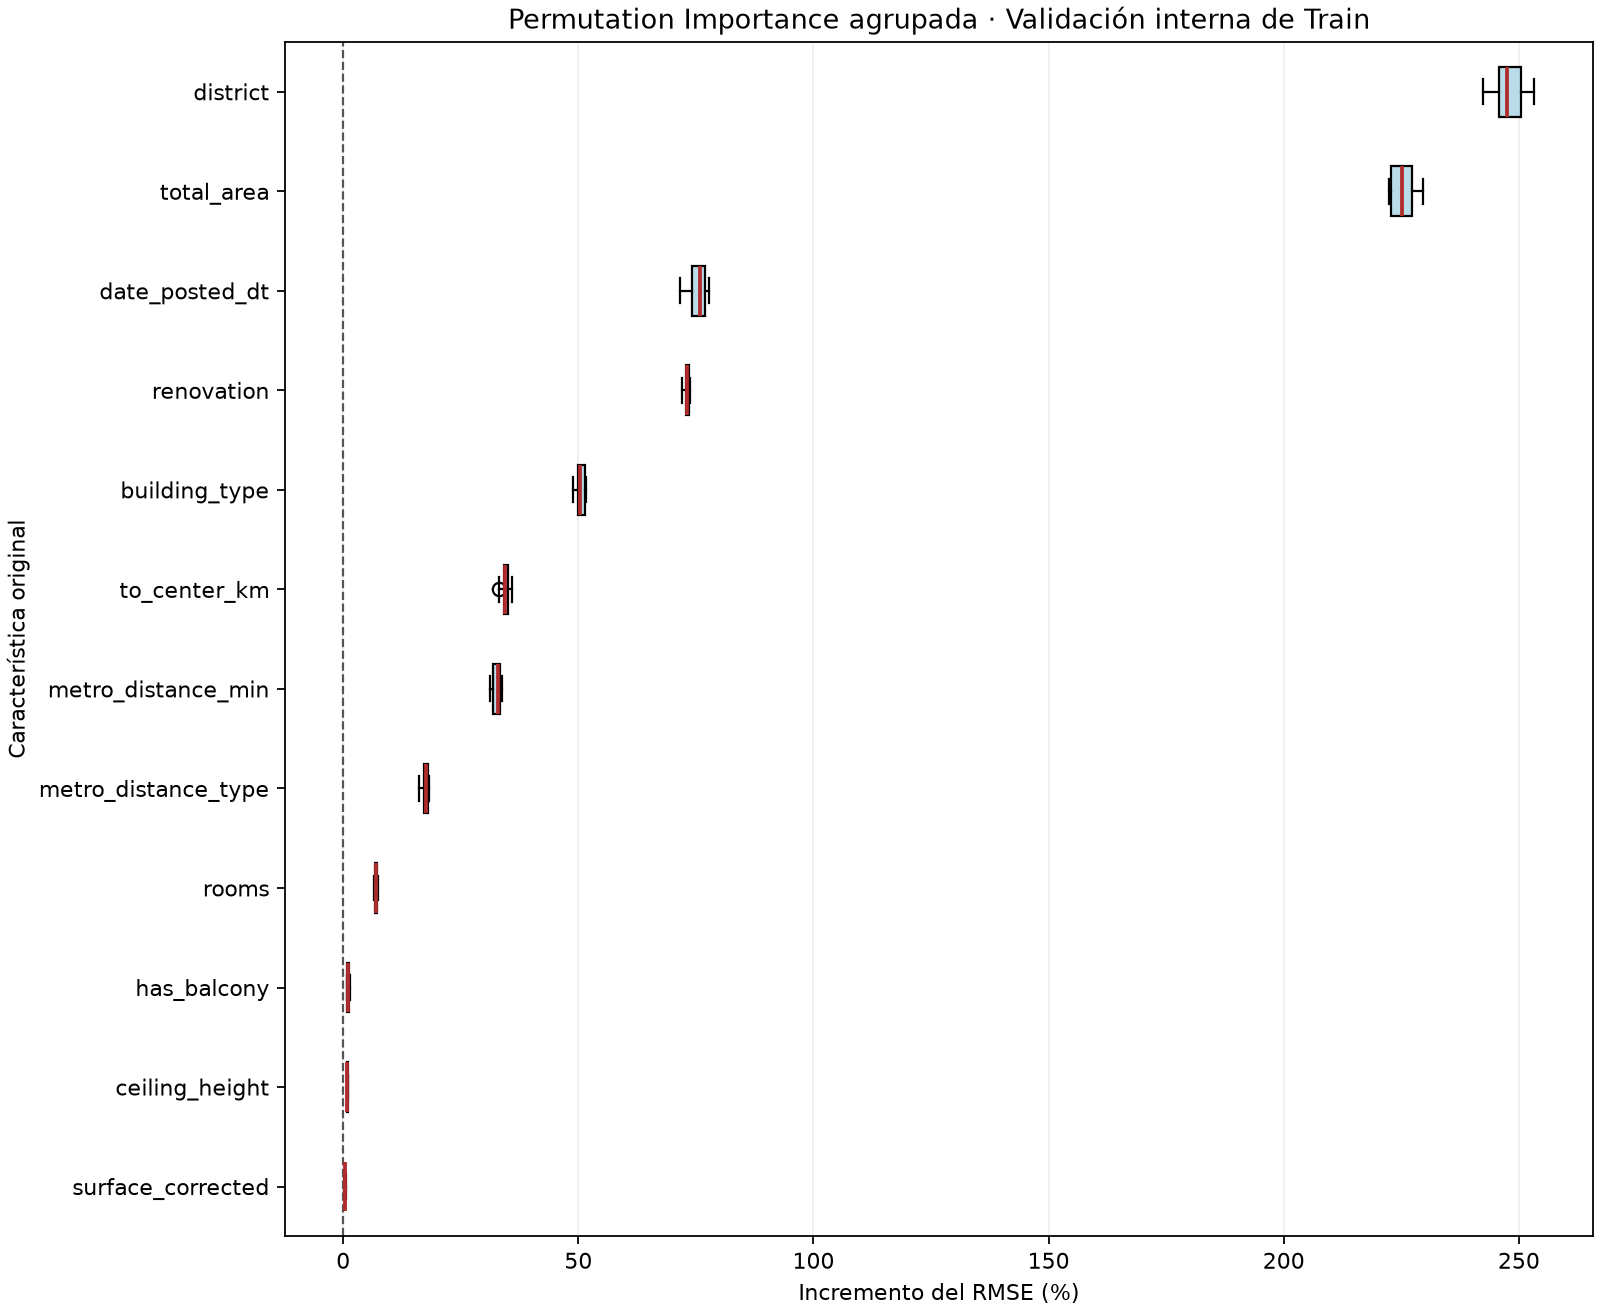

Mayores medianas de incremento del RMSE: `district` (247.4 %), `total_area` (225.2 %), `date_posted_dt` (75.9 %); 10 permutaciones por grupo.  
Las columnas de cada grupo se permutan conjuntamente respecto de price_rub; no mide efectos causales ni magnitudes de coeficientes OLS.  
Se reutiliza la validación de selección; correlaciones entre características pueden afectar la importancia.

In [19]:
display(Image(filename=str(backward['salida'] / 'importancia_caracteristicas_boxplot.png')))
display(Markdown(s.interpretar_importancia(backward)))


In [20]:
display(Markdown(s.confirmacion_presentacion(backward)))


Recuperado de MLflow; sin nueva selección ni ajuste final · **FINISHED** · [Backward_03_Log_177_Grupos_OLS](https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/5/runs/74f261e8575b4858ad9a88fd9373bc76)

## 5. Forward Stepwise Selection — 177 predictoras
Experimento independiente del Forward histórico: **177 columnas candidatas / 23 características originales**, incluidas `to_center_km`, `living_area` y `rooms`, con exclusiones vacías. Se reutiliza el algoritmo agrupado de `scripts/seleccion_modelos.py`; los bloques One-Hot ingresan completos.
Desde el intercepto, cada incorporación debe mejorar el RMSE interno en RUB al menos **0,5 %** frente al modelo anterior. Se detiene en el primer rechazo, al alcanzar **12 grupos** o al agotar las candidatas. La partición es exactamente la misma (80/20, semilla 42); objetivo `ln(price_rub)`, inversa `exp`, sin corrección de sesgo. El OLS definitivo se reajusta con todo Train y debe presentar rango completo.
Referencia: `OLS_02_Log_Target` (177 predictoras). Run exclusivo: `Forward_04_Log_177_Grupos`. Una ejecución nueva exige `modo="nuevo"` y un nombre libre; tras el registro, se recupera estrictamente sin repetir la selección ni el ajuste final. Los CSV y los modelos anteriores se conservan.


In [21]:
with sesion.paso():
    datos_forward_177 = s.cargar_forward_177(datos)
    forward_177 = s.ejecutar_presentacion(datos_forward_177, "forward", modo="recuperar", nombre_run=s.NOMBRE_RUN_177)


In [22]:
resumen_177, coeficientes_177 = forward_177['caracteristicas_md'].split("\n\n", 1)
display(Markdown(resumen_177 + "\n\n<details><summary>Columnas transformadas y coeficientes OLS</summary>\n\n"
                 + coeficientes_177 + "\n\n</details>"))


| Orden | Característica seleccionada | Cantidad de predictores |
|---|---|---|
| 1 | `district` | 128 |
| 2 | `total_area` | 1 |
| 3 | `renovation` | 3 |
| 4 | `date_posted_dt` | 1 |
| 5 | `building_type` | 5 |
| 6 | `metro_distance_min` | 1 |
| 7 | `metro_distance_type` | 1 |
| 8 | `rooms` | 1 |
| Total | 8 características | 141 predictores |

<details><summary>Columnas transformadas y coeficientes OLS</summary>

| Característica original | Columna transformada | Coeficiente OLS [ln(RUB)] |
|---|---|---|
| district | district_akademichesky | 0.1738 |
| district | district_alekseevsky | 0.0019 |
| district | district_altufyevsky | -0.3459 |
| district | district_arbat | 0.7782 |
| district | district_babushkinsky | -0.2468 |
| district | district_basmanny | 0.5165 |
| district | district_begovoy | 0.1548 |
| district | district_beskudnikovsky | -0.3153 |
| district | district_bibirevo | -0.3091 |
| district | district_biryulyovo_vostochnoye | -0.4538 |
| district | district_biryulyovo_zapadnoye | -0.4253 |
| district | district_bogorodskoye | -0.2254 |
| district | district_brateyevo | -0.4078 |
| district | district_butyrsky | -0.0635 |
| district | district_chertanovo_severnoye | -0.2226 |
| district | district_chertanovo_tsentralnoye | -0.3363 |
| district | district_chertanovo_yuzhnoye | -0.2750 |
| district | district_cheryomushki | 0.1643 |
| district | district_danilovsky | 0.0326 |
| district | district_desyonovskoye | -0.6320 |
| district | district_dmitrovsky | -0.3583 |
| district | district_donskoy | 0.1078 |
| district | district_dorogomilovo | 0.4881 |
| district | district_fili_davydkovo | 0.1699 |
| district | district_filimonkovskoye | -0.7517 |
| district | district_filyovsky_park | 0.2233 |
| district | district_gagarinsky | 0.3163 |
| district | district_golovinsky | -0.2333 |
| district | district_golyanovo | -0.3298 |
| district | district_ivanovskoye | -0.3180 |
| district | district_izmaylovo | -0.1345 |
| district | district_khamovniki | 0.7899 |
| district | district_khoroshyovo_mnyovniki | 0.0875 |
| district | district_khoroshyovsky | 0.1805 |
| district | district_khovrino | -0.3473 |
| district | district_kievsky | -0.9929 |
| district | district_klyonovskoye | -1.0697 |
| district | district_kokoshkino | -0.7746 |
| district | district_konkovo | -0.0264 |
| district | district_koptevo | -0.2183 |
| district | district_kosino_ukhtomsky | -0.4123 |
| district | district_kotlovka | 0.0580 |
| district | district_krasnopakhorskoye | -1.0113 |
| district | district_krasnoselsky | 0.4597 |
| district | district_krylatskoye | 0.2014 |
| district | district_kuntsevo | 0.0626 |
| district | district_kurkino | -0.0254 |
| district | district_levoberezhny | -0.2141 |
| district | district_lianozovo | -0.3574 |
| district | district_lomonosovsky | 0.2952 |
| district | district_losinoostrovsky | -0.2830 |
| district | district_marfino | -0.2384 |
| district | district_marushkinskoye | -0.7989 |
| district | district_maryina_roshcha | 0.0212 |
| district | district_meshchansky | 0.5120 |
| district | district_metrogorodok | -0.3007 |
| district | district_mikhaylovo_yartsevskoye | -1.0793 |
| district | district_mitino | -0.1520 |
| district | district_molzhaninovsky | -0.4932 |
| district | district_moskovsky | -0.5689 |
| district | district_moskvorechye_saburovo | -0.2603 |
| district | district_mosrentgen | -0.4778 |
| district | district_mozhaysky | -0.0274 |
| district | district_nagatino_sadovniki | -0.1257 |
| district | district_nagatinsky_zaton | -0.1034 |
| district | district_nagorny | -0.0710 |
| district | district_novo_peredelkino | -0.2597 |
| district | district_novofyodorovskoye | -1.0091 |
| district | district_novogireyevo | -0.2142 |
| district | district_novokosino | -0.3153 |
| district | district_obruchevsky | 0.0904 |
| district | district_ochakovo_matveyevskoye | -0.0211 |
| district | district_orekhovo_borisovo_severnoye | -0.3964 |
| district | district_orekhovo_borisovo_yuzhnoye | -0.4101 |
| district | district_ostankinsky | -0.0185 |
| district | district_otradnoye | -0.2513 |
| district | district_perovo | -0.1143 |
| district | district_pervomayskoye | -1.0224 |
| district | district_pokrovskoye_streshnevo | -0.0361 |
| district | district_preobrazhenskoye | -0.0404 |
| district | district_presnensky | 0.7159 |
| district | district_prospekt_vernadskogo | 0.2774 |
| district | district_ramenki | 0.3000 |
| district | district_rogovskoye | -1.0096 |
| district | district_rostokino | -0.2294 |
| district | district_ryazanovskoye | -0.7529 |
| district | district_savyolovsky | 0.0888 |
| district | district_severnoye_butovo | -0.2079 |
| district | district_severnoye_izmaylovo | -0.1918 |
| district | district_severnoye_medvedkovo | -0.2747 |
| district | district_severnoye_tushino | -0.1770 |
| district | district_severny | -0.4430 |
| district | district_shchapovskoye | -1.1066 |
| district | district_shcherbinka | -0.6256 |
| district | district_shchukino | 0.1613 |
| district | district_sokol | 0.1430 |
| district | district_sokolinaya_gora | -0.2211 |
| district | district_sokolniki | 0.0369 |
| district | district_solntsevo | -0.1921 |
| district | district_sosenskoye | -0.5679 |
| district | district_strogino | 0.2190 |
| district | district_sviblovo | -0.2016 |
| district | district_tagansky | 0.4755 |
| district | district_timiryazevsky | -0.0325 |
| district | district_troitsk | -0.8561 |
| district | district_troparyovo_nikulino | 0.1928 |
| district | district_tsaritsyno | -0.3575 |
| district | district_tverskoy | 0.7624 |
| district | district_tyoply_stan | -0.1027 |
| district | district_veshnyaki | -0.4033 |
| district | district_vnukovo | -0.2990 |
| district | district_vnukovskoye | -0.5516 |
| district | district_voronovskoye | -1.0033 |
| district | district_voskresenskoye | -0.6456 |
| district | district_vostochnoye_izmaylovo | -0.2604 |
| district | district_vostochny | -0.4423 |
| district | district_voykovsky | -0.0830 |
| district | district_yakimanka | 0.7129 |
| district | district_yaroslavsky | -0.3067 |
| district | district_yasenevo | 0.0731 |
| district | district_yuzhnoye_butovo | -0.2715 |
| district | district_yuzhnoye_medvedkovo | -0.3057 |
| district | district_yuzhnoye_tushino | -0.1099 |
| district | district_zamoskvorechye | 0.6021 |
| district | district_zapadnoye_degunino | -0.3417 |
| district | district_zelenograd | -0.6724 |
| district | district_zyablikovo | -0.3991 |
| district | district_zyuzino | 0.0052 |
| total_area | total_area | 0.0159 |
| renovation | renovation_designer | 0.3053 |
| renovation | renovation_euro | 0.1453 |
| renovation | renovation_no_renovation | -0.1108 |
| date_posted_dt | months_since_start | 0.0073 |
| building_type | building_type_khrushchev | -0.2104 |
| building_type | building_type_modern_panel | -0.0481 |
| building_type | building_type_monolith | 0.0453 |
| building_type | building_type_panel | -0.1327 |
| building_type | building_type_stalin | 0.1541 |
| metro_distance_min | metro_distance_min | -0.0017 |
| metro_distance_type | metro_distance_type | -0.1251 |
| rooms | rooms | -0.0236 |

</details>

In [23]:
display(Markdown(s.tabla_metricas_presentacion(forward_177)))


| Evaluación | Métrica | Forward Stepwise Selection — 177 predictoras |
|---|---|---|
| Train | R² [ln(RUB)] | 0.953968 |
| Train | R² ajustado [ln(RUB)] | 0.953796 |
| Train | MAE (RUB) | 1,113,229.451 |
| Train | RMSE (RUB) | 1,602,567.630 |
| Train | AIC [ln(RUB)] | -53,202.517 |
| Train | BIC [ln(RUB)] | -51,989.138 |
| Train | VIF máximo | 8.554 |
| Train | Número de condición | 13,163.344 |
| Train | Breusch–Pagan (p) | 2.275e-106 |
| Train | Jarque–Bera (p) | 1.516e-53 |
| Validación interna | RMSE (RUB) | 1,603,607.587 |

In [24]:
display(Markdown(s.interpretar_presentacion(forward_177)))


El OLS utiliza 8 características originales y 141 columnas predictoras, más el intercepto.  
R² ajustado log=0.95380; RMSE Train=1,602,568 RUB y validación interna=1,603,608 RUB.  
Persisten límites de homocedasticidad (BP p=2.28e-106) y normalidad (JB p=1.52e-53).  
La validación se utilizó para seleccionar: sus métricas no son una evaluación independiente. exp sin corrección puede sesgar el precio esperado.

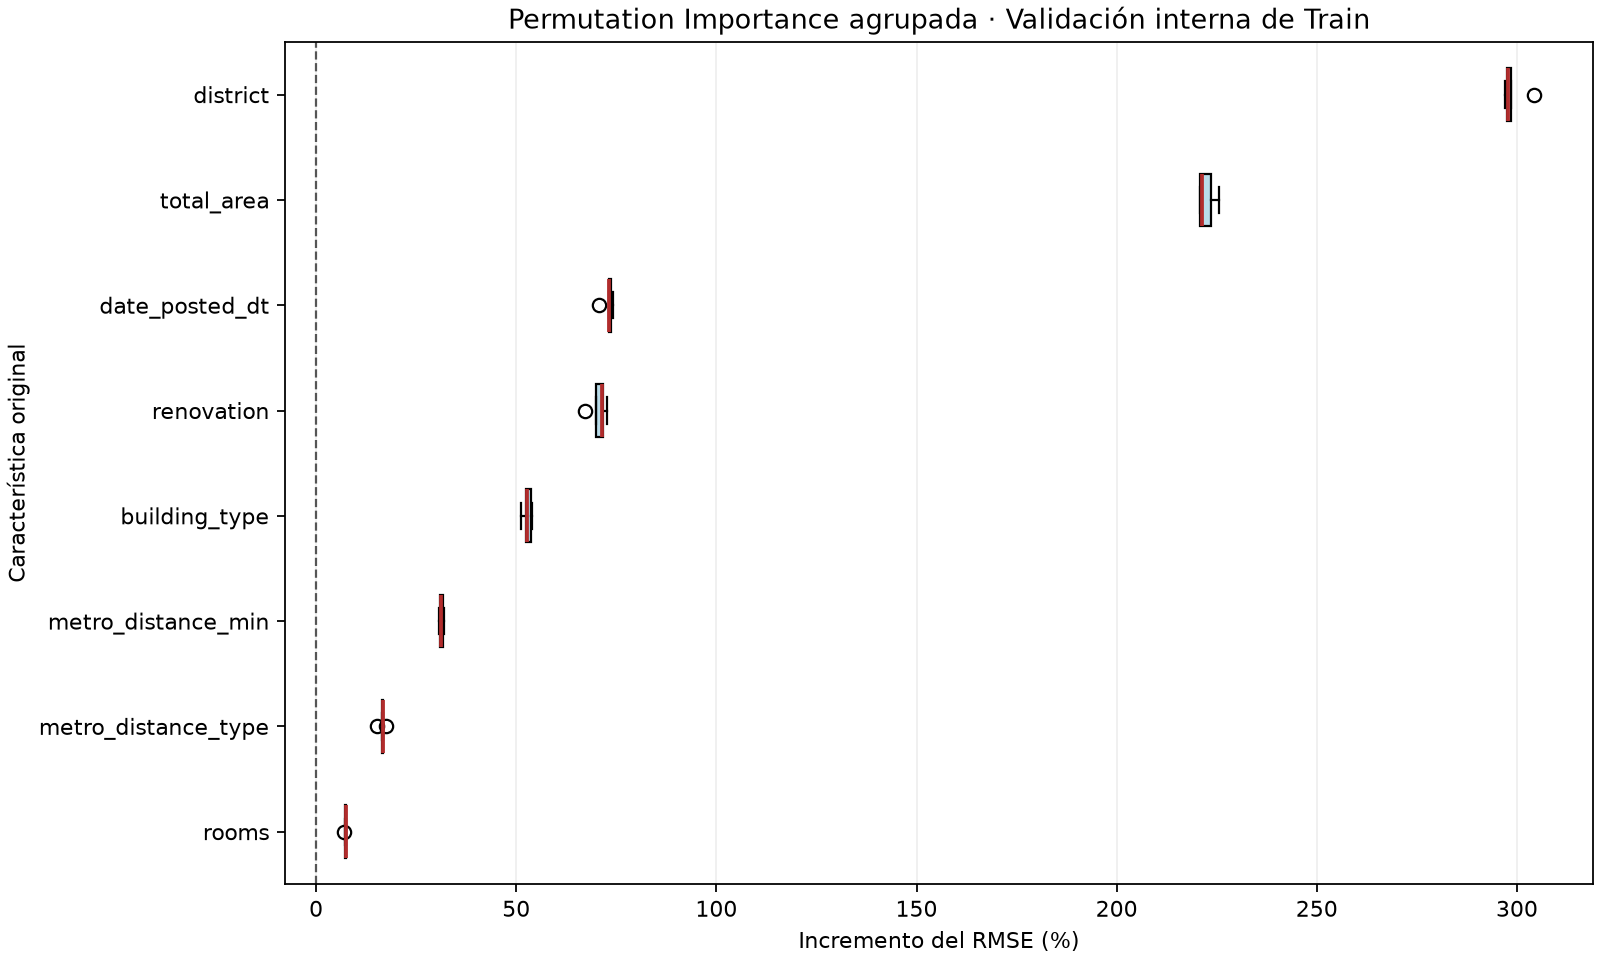

Mayores medianas de incremento del RMSE: `district` (297.7 %), `total_area` (221.2 %), `date_posted_dt` (73.2 %); 5 permutaciones por grupo.  
Las columnas de cada grupo se permutan conjuntamente respecto de price_rub; no mide efectos causales ni magnitudes de coeficientes OLS.  
Se reutiliza la validación de selección; correlaciones entre características pueden afectar la importancia.

In [25]:
display(Image(filename=str(forward_177['salida'] / 'importancia_caracteristicas_boxplot.png')))
display(Markdown(s.interpretar_importancia(forward_177)))


In [26]:
display(Markdown(s.confirmacion_presentacion(forward_177)))


Recuperado de MLflow; sin nueva selección ni ajuste final · **FINISHED** · [Forward_04_Log_177_Grupos](https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/5/runs/9b5b90c245cb4fd8a804c1d0e4c3ff7b)

### Comparación específica: Forward de 174 y 177 predictoras
El algoritmo y la configuración se mantienen. Se distingue el universo disponible del subconjunto elegido y se informa cuándo ingresan las tres características habilitadas.


In [27]:
tabla_forward_177, analisis_forward_177 = s.comparacion_forward_presentacion(forward, forward_177)
display(Markdown(tabla_forward_177))
display(Markdown(analisis_forward_177))


| Método | Características | Columnas OLS | R² ajustado Train [log] | RMSE Train (RUB) | RMSE interno (RUB) | AIC [log] | BIC [log] |
|---|---|---|---|---|---|---|---|
| Forward Stepwise Selection — 174 predictoras | 7 | 140 | 0.953405 | 1,609,441.446 | 1,612,615.151 | -52,883.105 | -51,678.271 |
| Forward Stepwise Selection — 177 predictoras | 8 | 141 | 0.953796 | 1,602,567.630 | 1,603,607.587 | -53,202.517 | -51,989.138 |
| Δ 177 − 174 | 1.000 | 1.000 | 3.914e-04 | -6,873.815 | -9,007.565 | -319.412 | -310.867 |

Universos iniciales: 174 columnas / 20 grupos frente a 177 columnas / 23 grupos. La tabla cuenta las características y columnas finales.  
Comunes: `building_type`, `date_posted_dt`, `district`, `metro_distance_min`, `metro_distance_type`, `renovation`, `total_area`. Exclusivas del histórico: Ninguna. Exclusivas del nuevo: `rooms`.  
`to_center_km`: disponible entre las candidatas, no seleccionada.  
`living_area`: disponible entre las candidatas, no seleccionada.  
`rooms`: incorporada en la iteración 8.  
Cambio del RMSE interno: -9,007.565 RUB (-0.559 %). Habilitar las tres variables reduce el error observado de selección. El conjunto seleccionado cambia.  
La validación interna se utilizó para seleccionar los modelos; no es una evaluación independiente sobre datos nuevos. Test no se utilizó.

## 6. Group Lasso + OLS — 177 predictoras
Experimento independiente: **177 columnas / 23 grupos originales**, incluidas `to_center_km`, `living_area` y `rooms`, sin exclusiones previas. Los bloques One-Hot se seleccionan completos. Referencia obligatoria: `Forward_04_Log_177_Grupos`, terminado y con los mismos índices internos 80/20 (semilla 42).
Se conserva Group Lasso ponderado por la raíz del rango de cada grupo: centrado del objetivo e intercepto sin penalización, `StandardScaler` ajustado solo en entrenamiento interno, FISTA con reinicio adaptativo y verificación KKT. Se recorren **40 lambdas**, de λmax a 0,001 × λmax; tolerancias de soporte 1e-6 y solver 1e-7, máximo 20.000 iteraciones.
Se comparan los mejores subconjuntos de cada tamaño de **1 a 12 grupos** en orden creciente, desde el intercepto, aceptando mejoras del RMSE interno ≥0,5 % frente al último aceptado. Un rechazo no detiene tamaños posteriores. Se conserva la grilla completa, incluidos los modelos no elegibles con más de 12 grupos. Sin ganador o convergencia no se registra un modelo válido.
El OLS definitivo se ajusta sin penalización con todo Train, sobre las escalas exportadas; objetivo `ln(price_rub)`, inversa `exp` sin corrección de sesgo, diseño de rango completo. El Run exclusivo es `GroupLasso_05_Log_177_Grupos_OLS`; una ejecución nueva requiere un nombre libre. Tras su registro, se recupera estrictamente sin volver a entrenar. Test no se utiliza.


In [28]:
with sesion.paso():
    datos_lasso_177 = s.cargar_presentacion(base, sesion, excluidas=(), cliente=datos['cliente'])
    lasso_177 = s.ejecutar_presentacion(datos_lasso_177, "lasso", modo="recuperar", anterior=forward_177,
                                      nombre_run=gl.NOMBRE_RUN_177)


In [29]:
resumen_lasso_177, coeficientes_lasso_177 = lasso_177['caracteristicas_md'].split("\n\n", 1)
display(Markdown(resumen_lasso_177 + "\n\n<details><summary>Columnas transformadas y coeficientes OLS</summary>\n\n"
                 + coeficientes_lasso_177 + "\n\n</details>"))


| Característica seleccionada | Cantidad de predictores |
|---|---|
| `total_area` | 1 |
| `living_area` | 1 |
| `ceiling_height` | 1 |
| `metro_distance_min` | 1 |
| `to_center_km` | 1 |
| `surface_corrected` | 1 |
| `has_balcony` | 1 |
| `metro_distance_type` | 1 |
| `building_type` | 5 |
| `renovation` | 3 |
| `district` | 128 |
| `date_posted_dt` | 1 |
| Total: 12 características | 145 predictores |

<details><summary>Columnas transformadas y coeficientes OLS</summary>

| Característica original | Columna transformada | Coeficiente OLS [ln(RUB)] |
|---|---|---|
| total_area | total_area | 0.0145 |
| living_area | living_area | 0.0002 |
| ceiling_height | ceiling_height | 0.0454 |
| metro_distance_min | metro_distance_min | -0.0017 |
| to_center_km | to_center_km | -0.0077 |
| surface_corrected | surface_corrected | -0.1577 |
| has_balcony | has_balcony | 0.0308 |
| metro_distance_type | metro_distance_type | -0.1249 |
| building_type | building_type_khrushchev | -0.2103 |
| building_type | building_type_modern_panel | -0.0479 |
| building_type | building_type_monolith | 0.0454 |
| building_type | building_type_panel | -0.1322 |
| building_type | building_type_stalin | 0.1324 |
| renovation | renovation_designer | 0.3051 |
| renovation | renovation_euro | 0.1450 |
| renovation | renovation_no_renovation | -0.1110 |
| district | district_akademichesky | 0.1765 |
| district | district_alekseevsky | -0.0071 |
| district | district_altufyevsky | -0.2884 |
| district | district_arbat | 0.7334 |
| district | district_babushkinsky | -0.2061 |
| district | district_basmanny | 0.4872 |
| district | district_begovoy | 0.1405 |
| district | district_beskudnikovsky | -0.2663 |
| district | district_bibirevo | -0.2581 |
| district | district_biryulyovo_vostochnoye | -0.3670 |
| district | district_biryulyovo_zapadnoye | -0.3459 |
| district | district_bogorodskoye | -0.2123 |
| district | district_brateyevo | -0.3522 |
| district | district_butyrsky | -0.0660 |
| district | district_chertanovo_severnoye | -0.1931 |
| district | district_chertanovo_tsentralnoye | -0.2896 |
| district | district_chertanovo_yuzhnoye | -0.2023 |
| district | district_cheryomushki | 0.1802 |
| district | district_danilovsky | 0.0141 |
| district | district_desyonovskoye | -0.4762 |
| district | district_dmitrovsky | -0.3021 |
| district | district_donskoy | 0.0879 |
| district | district_dorogomilovo | 0.4679 |
| district | district_fili_davydkovo | 0.1821 |
| district | district_filimonkovskoye | -0.6099 |
| district | district_filyovsky_park | 0.2369 |
| district | district_gagarinsky | 0.3070 |
| district | district_golovinsky | -0.1951 |
| district | district_golyanovo | -0.2869 |
| district | district_ivanovskoye | -0.2782 |
| district | district_izmaylovo | -0.1119 |
| district | district_khamovniki | 0.7616 |
| district | district_khoroshyovo_mnyovniki | 0.1026 |
| district | district_khoroshyovsky | 0.1693 |
| district | district_khovrino | -0.2858 |
| district | district_kievsky | -0.5299 |
| district | district_klyonovskoye | -0.7057 |
| district | district_kokoshkino | -0.6138 |
| district | district_konkovo | 0.0243 |
| district | district_koptevo | -0.1862 |
| district | district_kosino_ukhtomsky | -0.3578 |
| district | district_kotlovka | 0.0693 |
| district | district_krasnopakhorskoye | -0.7587 |
| district | district_krasnoselsky | 0.4354 |
| district | district_krylatskoye | 0.2424 |
| district | district_kuntsevo | 0.0925 |
| district | district_kurkino | 0.0766 |
| district | district_levoberezhny | -0.1573 |
| district | district_lianozovo | -0.2873 |
| district | district_lomonosovsky | 0.3022 |
| district | district_losinoostrovsky | -0.2323 |
| district | district_marfino | -0.2205 |
| district | district_marushkinskoye | -0.6189 |
| district | district_maryina_roshcha | -0.0010 |
| district | district_meshchansky | 0.4778 |
| district | district_metrogorodok | -0.2744 |
| district | district_mikhaylovo_yartsevskoye | -0.7841 |
| district | district_mitino | -0.0605 |
| district | district_molzhaninovsky | -0.3537 |
| district | district_moskovsky | -0.4426 |
| district | district_moskvorechye_saburovo | -0.2254 |
| district | district_mosrentgen | -0.4055 |
| district | district_mozhaysky | 0.0163 |
| district | district_nagatino_sadovniki | -0.1218 |
| district | district_nagatinsky_zaton | -0.0925 |
| district | district_nagorny | -0.0598 |
| district | district_novo_peredelkino | -0.1641 |
| district | district_novofyodorovskoye | -0.5787 |
| district | district_novogireyevo | -0.1853 |
| district | district_novokosino | -0.2565 |
| district | district_obruchevsky | 0.1196 |
| district | district_ochakovo_matveyevskoye | 0.0128 |
| district | district_orekhovo_borisovo_severnoye | -0.3385 |
| district | district_orekhovo_borisovo_yuzhnoye | -0.3389 |
| district | district_ostankinsky | -0.0151 |
| district | district_otradnoye | -0.2147 |
| district | district_perovo | -0.0931 |
| district | district_pervomayskoye | -0.7139 |
| district | district_pokrovskoye_streshnevo | 0.0031 |
| district | district_preobrazhenskoye | -0.0406 |
| district | district_presnensky | 0.6822 |
| district | district_prospekt_vernadskogo | 0.3098 |
| district | district_ramenki | 0.3137 |
| district | district_rogovskoye | -0.5645 |
| district | district_rostokino | -0.2127 |
| district | district_ryazanovskoye | -0.5641 |
| district | district_savyolovsky | 0.0706 |
| district | district_severnoye_butovo | -0.1195 |
| district | district_severnoye_izmaylovo | -0.1503 |
| district | district_severnoye_medvedkovo | -0.2210 |
| district | district_severnoye_tushino | -0.1114 |
| district | district_severny | -0.3487 |
| district | district_shchapovskoye | -0.8381 |
| district | district_shcherbinka | -0.4661 |
| district | district_shchukino | 0.1888 |
| district | district_sokol | 0.1534 |
| district | district_sokolinaya_gora | -0.2172 |
| district | district_sokolniki | 0.0219 |
| district | district_solntsevo | -0.1095 |
| district | district_sosenskoye | -0.4355 |
| district | district_strogino | 0.2747 |
| district | district_sviblovo | -0.1780 |
| district | district_tagansky | 0.4465 |
| district | district_timiryazevsky | -0.0308 |
| district | district_troitsk | -0.6343 |
| district | district_troparyovo_nikulino | 0.2421 |
| district | district_tsaritsyno | -0.3004 |
| district | district_tverskoy | 0.7230 |
| district | district_tyoply_stan | -0.0308 |
| district | district_veshnyaki | -0.3669 |
| district | district_vnukovo | -0.1641 |
| district | district_vnukovskoye | -0.4368 |
| district | district_voronovskoye | -0.6261 |
| district | district_voskresenskoye | -0.5223 |
| district | district_vostochnoye_izmaylovo | -0.2178 |
| district | district_vostochny | -0.3766 |
| district | district_voykovsky | -0.0625 |
| district | district_yakimanka | 0.6760 |
| district | district_yaroslavsky | -0.2530 |
| district | district_yasenevo | 0.1471 |
| district | district_yuzhnoye_butovo | -0.1464 |
| district | district_yuzhnoye_medvedkovo | -0.2598 |
| district | district_yuzhnoye_tushino | -0.0549 |
| district | district_zamoskvorechye | 0.5592 |
| district | district_zapadnoye_degunino | -0.2970 |
| district | district_zelenograd | -0.4451 |
| district | district_zyablikovo | -0.3275 |
| district | district_zyuzino | 0.0304 |
| date_posted_dt | months_since_start | 0.0073 |

</details>

In [30]:
display(Markdown(s.tabla_metricas_presentacion(lasso_177, anterior=forward_177)))


| Evaluación | Métrica | Forward Stepwise Selection — 177 predictoras | Group Lasso + OLS — 177 predictoras | Δ nuevo − anterior |
|---|---|---|---|---|
| Train | R² [ln(RUB)] | 0.953968 | 0.955048 | 0.001080 |
| Train | R² ajustado [ln(RUB)] | 0.953796 | 0.954876 | 0.001080 |
| Train | MAE (RUB) | 1,113,229.451 | 1,100,663.681 | -12,565.770 |
| Train | RMSE (RUB) | 1,602,567.630 | 1,587,916.804 | -14,650.826 |
| Train | AIC [ln(RUB)] | -53,202.517 | -54,096.635 | -894.118 |
| Train | BIC [ln(RUB)] | -51,989.138 | -52,849.076 | -859.938 |
| Train | VIF máximo | 8.554 | 102.534 | 93.980 |
| Train | Número de condición | 13,163.344 | 18,631.331 | 5,467.987 |
| Train | Breusch–Pagan (p) | 2.275e-106 | 3.218e-103 | 3.216e-103 |
| Train | Jarque–Bera (p) | 1.516e-53 | 1.633e-50 | 1.631e-50 |
| Validación interna | RMSE (RUB) | 1,603,607.587 | 1,589,425.419 | -14,182.168 |

In [31]:
display(Markdown(s.interpretar_presentacion(lasso_177, anterior=forward_177)))
display(Markdown(gl.resumen_numerico_presentacion(lasso_177)))
diagnosticos_lasso_177 = lasso_177['metricas']
display(Markdown(
    f"Aunque el OLS es identificable, conserva colinealidad elevada: VIF máximo "
    f"{diagnosticos_lasso_177['train_vif_max']:.1f} y número de condición "
    f"{diagnosticos_lasso_177['train_condition_number']:,.0f}. "
    "El rango completo no asegura estabilidad de los coeficientes; su interpretación requiere cautela."
))


El OLS utiliza 12 características originales y 145 columnas predictoras, más el intercepto.  
R² ajustado log=0.95488; RMSE Train=1,587,917 RUB y validación interna=1,589,425 RUB.  
Frente a Forward, cambia +4 características y el RMSE interno -0.884 %; no simplifica el modelo.  
Persisten límites de homocedasticidad (BP p=3.22e-103) y normalidad (JB p=1.63e-50).  
La validación se utilizó para seleccionar: sus métricas no son una evaluación independiente. exp sin corrección puede sesgar el precio esperado.

Universo: 177 columnas / 23 grupos; Gram de rango 177/177, condición 972.5. Se evaluaron las 40 lambdas: 16 configuraciones con más de 12 grupos se conservaron como no elegibles. Todas convergieron; máximo residuo KKT relativo 9.97e-08 (tolerancia 1e-7). No se excluyeron columnas ni se modificaron hiperparámetros; el OLS definitivo usa las escalas exportadas.

Aunque el OLS es identificable, conserva colinealidad elevada: VIF máximo 102.5 y número de condición 18,631. El rango completo no asegura estabilidad de los coeficientes; su interpretación requiere cautela.

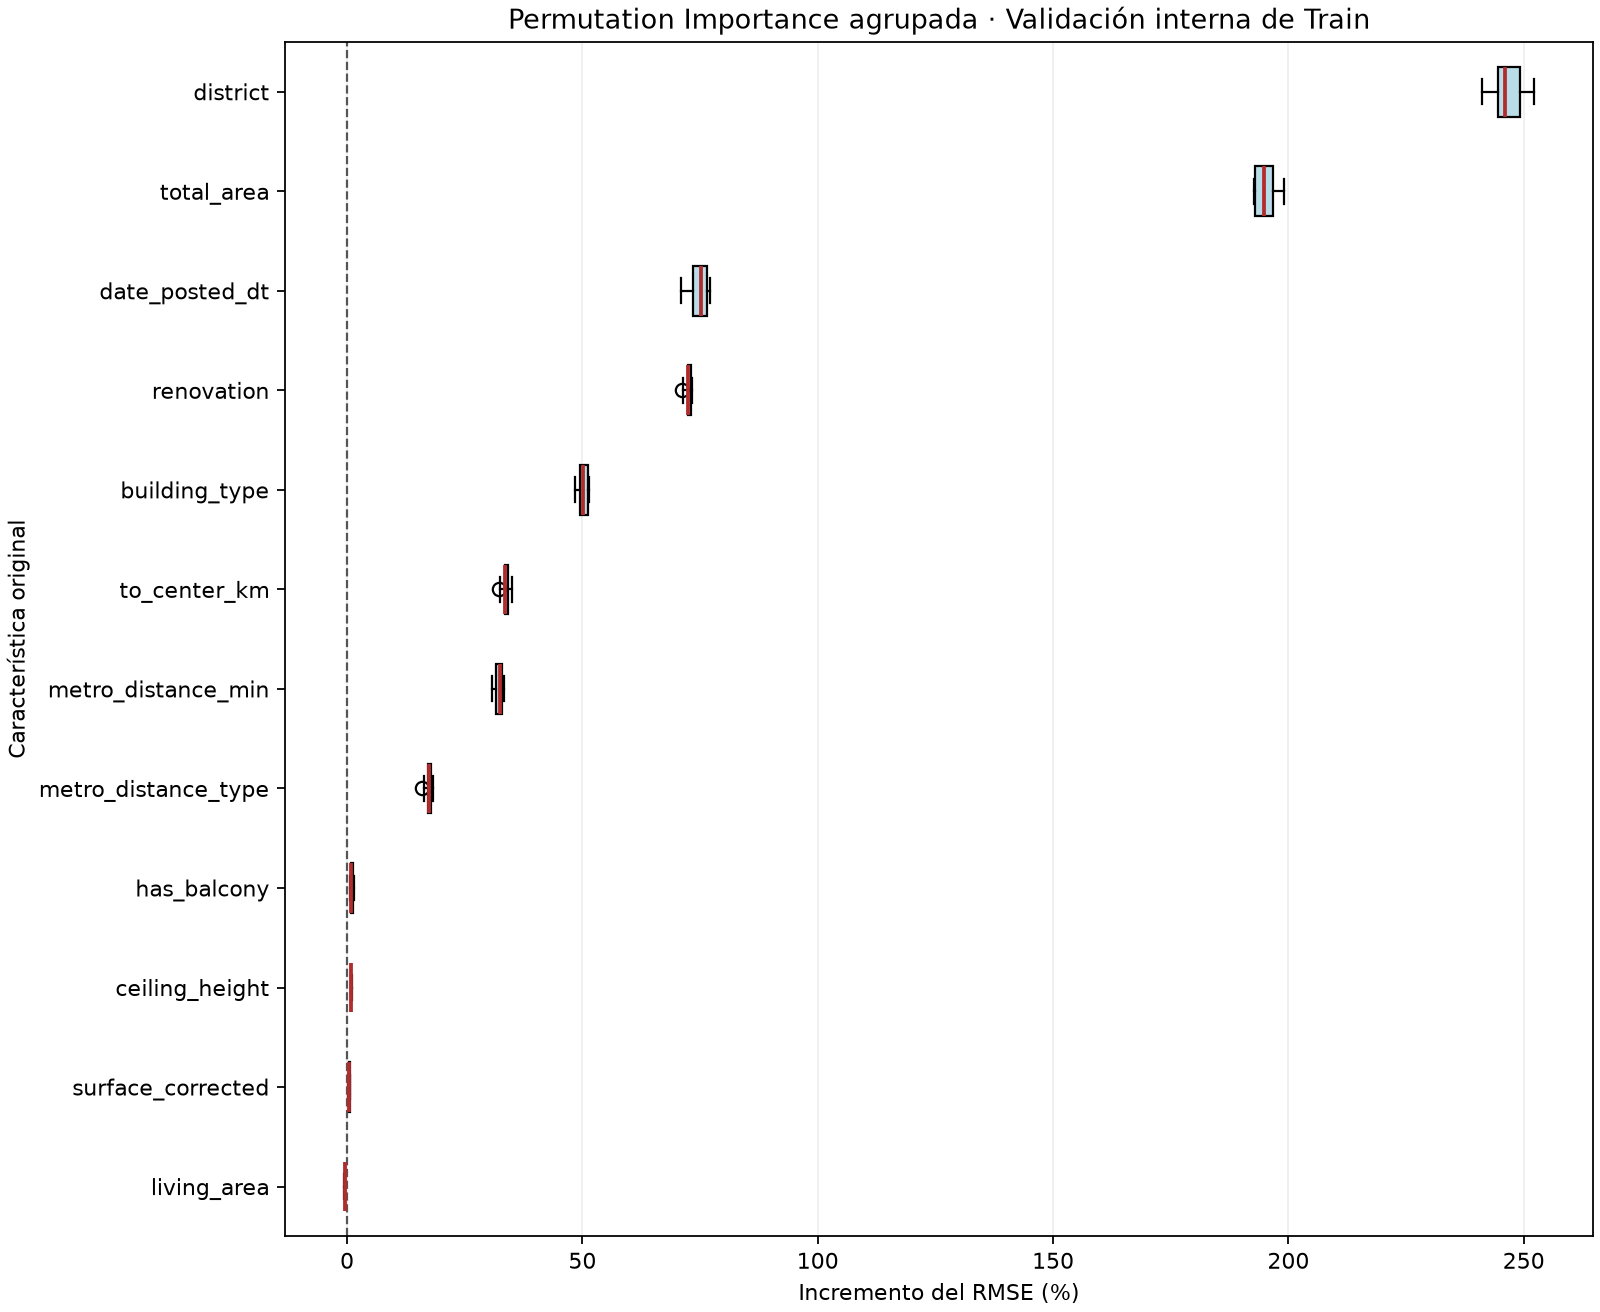

Mayores medianas de incremento del RMSE: `district` (246.1 %), `total_area` (194.8 %), `date_posted_dt` (75.2 %); 10 permutaciones por grupo.  
Las columnas de cada grupo se permutan conjuntamente respecto de price_rub; no mide efectos causales ni magnitudes de coeficientes OLS.  
Se reutiliza la validación de selección; correlaciones entre características pueden afectar la importancia.

In [32]:
display(Image(filename=str(lasso_177['salida'] / 'importancia_caracteristicas_boxplot.png')))
display(Markdown(s.interpretar_importancia(lasso_177)))


In [33]:
display(Markdown(s.confirmacion_presentacion(lasso_177)))


Recuperado de MLflow; sin nueva selección ni ajuste final · **FINISHED** · [GroupLasso_05_Log_177_Grupos_OLS](https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/5/runs/cda36a216ba1492eb1e87049344159c3)

### Comparación específica: universo inicial de 177 columnas
Forward, Group Lasso + OLS y Backward comparten candidatas, observaciones internas y escalas. Las características seleccionadas pueden diferir; los RMSE de selección no constituyen una evaluación independiente.


In [34]:
tabla_177, coincidencias_177, analisis_177 = s.comparacion_177_presentacion(forward_177, lasso_177, backward)
display(Markdown(tabla_177))
display(Markdown(coincidencias_177))
display(Markdown(analisis_177))


| Método | Características | Columnas OLS | R² ajustado Train [log] | RMSE Train (RUB) | RMSE interno (RUB) | AIC [log] | BIC [log] |
|---|---|---|---|---|---|---|---|
| Forward Selection | 8 | 141 | 0.953796 | 1,602,567.630 | 1,603,607.587 | -53,202.517 | -51,989.138 |
| Group Lasso + OLS | 12 | 145 | 0.954876 | 1,587,916.804 | 1,589,425.419 | -54,096.635 | -52,849.076 |
| Backward Selection | 12 | 145 | 0.955228 | 1,581,589.473 | 1,581,085.284 | -54,393.951 | -53,146.392 |

Comunes a los tres: `building_type`, `date_posted_dt`, `district`, `metro_distance_min`, `metro_distance_type`, `renovation`, `total_area`.  
Exclusivas de Forward Selection: Ninguna.  
Exclusivas de Group Lasso + OLS: `living_area`.  
Exclusivas de Backward Selection: Ninguna.  
Compartidas solo por Forward Selection y Group Lasso + OLS: Ninguna.  
Compartidas solo por Forward Selection y Backward Selection: `rooms`.  
Compartidas solo por Group Lasso + OLS y Backward Selection: `ceiling_height`, `has_balcony`, `surface_corrected`, `to_center_km`.

`to_center_km` — Forward — 177: no; Group Lasso + OLS — 177: sí; Backward — 177: sí.  
`living_area` — Forward — 177: no; Group Lasso + OLS — 177: sí; Backward — 177: no.  
`rooms` — Forward — 177: sí; Group Lasso + OLS — 177: no; Backward — 177: sí.  
Backward — 177 obtuvo el menor RMSE interno (1,581,085 RUB). El universo inicial de 177 columnas y la partición son compartidos. La validación participó en la selección; esta comparación no constituye una evaluación independiente sobre datos nuevos.

## 7. Comparación final
R² ajustado, AIC y BIC corresponden a `ln(price_rub)` sobre las mismas filas de Train. Los RMSE se expresan en RUB y distinguen Train de validación interna.

Forward y Group Lasso parten de 174 columnas; Backward y el nuevo Forward, de 177. La comparación es descriptiva. La validación interna participa en la selección y no constituye una evaluación independiente sobre datos nuevos.

La comparación específica de 177 candidatas mantiene constante el universo inicial; la tabla general conserva también los dos experimentos históricos de 174 columnas.


In [35]:
tabla_final, coincidencias = s.comparacion_final_presentacion(forward, lasso, backward, forward_177=forward_177, lasso_177=lasso_177)
display(Markdown(tabla_final))
display(Markdown(coincidencias))


| Método | Características | Columnas OLS | R² ajustado Train [log] | RMSE Train (RUB) | RMSE interno (RUB) | AIC [log] | BIC [log] | Columnas candidatas | Grupos candidatos |
|---|---|---|---|---|---|---|---|---|---|
| Forward Selection — 174 predictoras | 7 | 140 | 0.953405 | 1,609,441.446 | 1,612,615.151 | -52,883.105 | -51,678.271 | 174 | 20 |
| Group Lasso + OLS — 174 predictoras | 11 | 144 | 0.954592 | 1,592,884.139 | 1,593,947.716 | -53,859.677 | -52,620.664 | 174 | 20 |
| Backward Selection | 12 | 145 | 0.955228 | 1,581,589.473 | 1,581,085.284 | -54,393.951 | -53,146.392 | 177 | 23 |
| Forward Selection — 177 predictoras | 8 | 141 | 0.953796 | 1,602,567.630 | 1,603,607.587 | -53,202.517 | -51,989.138 | 177 | 23 |
| Group Lasso + OLS — 177 predictoras | 12 | 145 | 0.954876 | 1,587,916.804 | 1,589,425.419 | -54,096.635 | -52,849.076 | 177 | 23 |

Comunes a los 5: `building_type`, `date_posted_dt`, `district`, `metro_distance_min`, `metro_distance_type`, `renovation`, `total_area`.  
Exclusivas de Forward Selection — 174 predictoras: Ninguna.  
Exclusivas de Group Lasso + OLS — 174 predictoras: `metro_to_center_km`.  
Exclusivas de Backward Selection: Ninguna.  
Exclusivas de Forward Selection — 177 predictoras: Ninguna.  
Exclusivas de Group Lasso + OLS — 177 predictoras: `living_area`.  
Compartidas solo por Group Lasso + OLS — 174 predictoras y Backward Selection y Group Lasso + OLS — 177 predictoras: `ceiling_height`, `has_balcony`, `surface_corrected`.  
Compartidas solo por Backward Selection y Forward Selection — 177 predictoras: `rooms`.  
Compartidas solo por Backward Selection y Group Lasso + OLS — 177 predictoras: `to_center_km`.

In [36]:
display(Markdown(s.conclusion_presentacion(forward, lasso, backward, forward_177=forward_177, lasso_177=lasso_177)))
sesion.cerrar()


Backward Selection obtuvo el menor RMSE interno (1,581,085 RUB). El menor número de características finales corresponde a Forward Selection — 174 predictoras (7 grupos); la mayor reducción proporcional corresponde a Forward Selection — 177 predictoras. Forward Selection — 174 predictoras: 20 → 7 grupos (65.0 % de reducción), 140 columnas finales; Group Lasso + OLS — 174 predictoras: 20 → 11 grupos (45.0 % de reducción), 144 columnas finales; Backward Selection: 23 → 12 grupos (47.8 % de reducción), 145 columnas finales; Forward Selection — 177 predictoras: 23 → 8 grupos (65.2 % de reducción), 141 columnas finales; Group Lasso + OLS — 177 predictoras: 23 → 12 grupos (47.8 % de reducción), 145 columnas finales. Menos grupos favorecen la interpretación, aunque los bloques OHE pueden conservar muchas columnas.  
Forward y Group Lasso históricos parten de 174 columnas; los nuevos Forward y Group Lasso y Backward parten de 177. La comparación es descriptiva: las diferencias no pueden atribuirse exclusivamente al algoritmo. AIC, BIC y R² ajustado corresponden al objetivo logarítmico sobre las mismas filas de Train.  
La validación interna participa en la selección y no constituye una evaluación independiente sobre datos nuevos. Test no se utilizó.